# Customer Churn: Data Quality Audit & Exploratory Analysis

**Objective:** produce a reproducible, analysis-ready dataset and a defensible data-quality report.
**Dataset:** synthetic customer records (`data/customer_churn_raw.csv`, 15 rows x 11 columns).

**Notebook flow:** 1. Load -> 2. Profile -> 3. Clean (with documented assumptions) -> 4. Validate -> 5. Summary statistics -> 6. Distributions & patterns -> 7. Export -> 8. Findings & limitations

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
Path("figures").mkdir(exist_ok=True)

raw = pd.read_csv("data/customer_churn_raw.csv")
df = raw.copy()
print(raw.shape)
raw.head()

(15, 11)


,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes


## 1. Profiling the raw data

In [2]:
# Columns, dtypes, non-null counts, unique values
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean()*100).round(1),
    "unique": raw.nunique(),
})
profile

,dtype,non_null,missing,missing_%,unique
CustomerID,str,15,0,0.0,15
Gender,str,15,0,0.0,2
Age,int64,15,0,0.0,15
TenureMonths,int64,15,0,0.0,15
SubscriptionType,str,15,0,0.0,3
MonthlyCharges,float64,15,0,0.0,3
TotalCharges,float64,15,0,0.0,15
ContractType,str,15,0,0.0,3
SupportTickets,int64,15,0,0.0,7
PaymentMethod,str,15,0,0.0,4


In [3]:
# Hidden missing values: blanks / placeholder strings in text columns
text_cols = raw.select_dtypes(include=["object", "string"]).columns
placeholders = {"", "na", "n/a", "null", "none", "nan", "unknown", "?", "-"}
hidden = {c: int(raw[c].astype(str).str.strip().str.lower().isin(placeholders).sum()) for c in text_cols}
print("Placeholder-style missing values per text column:", hidden)

# Whitespace / casing inconsistencies
ws = {c: int((raw[c] != raw[c].str.strip()).sum()) for c in text_cols}
print("Values with leading/trailing whitespace:", ws)

# Category labels
for c in ["Gender", "SubscriptionType", "ContractType", "PaymentMethod", "Churn"]:
    print(f"\n{c}:", raw[c].value_counts(dropna=False).to_dict())

Placeholder-style missing values per text column: {'CustomerID': 0, 'Gender': 0, 'SubscriptionType': 0, 'ContractType': 0, 'PaymentMethod': 0, 'Churn': 0}
Values with leading/trailing whitespace: {'CustomerID': 0, 'Gender': 0, 'SubscriptionType': 0, 'ContractType': 0, 'PaymentMethod': 0, 'Churn': 0}

Gender: {'Female': 8, 'Male': 7}

SubscriptionType: {'Basic': 7, 'Pro': 4, 'Enterprise': 4}

ContractType: {'Month-to-Month': 7, 'One Year': 4, 'Two Year': 4}

PaymentMethod: {'Credit Card': 6, 'UPI': 4, 'Bank Transfer': 3, 'Debit Card': 2}

Churn: {'No': 8, 'Yes': 7}


In [4]:
# Duplicates: full-row and on the primary key
print("Fully duplicated rows :", raw.duplicated().sum())
print("Duplicate CustomerIDs  :", raw["CustomerID"].duplicated().sum())
print("CustomerID format OK   :", raw["CustomerID"].str.fullmatch(r"CUST-\d{4}").all())

Fully duplicated rows : 0
Duplicate CustomerIDs  : 0
CustomerID format OK   : True


In [5]:
# Outliers: IQR rule (1.5 x IQR) and |z| > 3 on numeric columns
num_cols = ["Age", "TenureMonths", "MonthlyCharges", "TotalCharges", "SupportTickets"]
rows = []
for c in num_cols:
    q1, q3 = raw[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    z = (raw[c] - raw[c].mean()) / raw[c].std()
    rows.append({"column": c, "min": raw[c].min(), "max": raw[c].max(),
                 "IQR_lower": lo, "IQR_upper": hi,
                 "IQR_outliers": int(((raw[c] < lo) | (raw[c] > hi)).sum()),
                 "|z|>3": int((z.abs() > 3).sum())})
outliers = pd.DataFrame(rows).round(2)
outliers

,column,min,max,IQR_lower,IQR_upper,IQR_outliers,|z|>3
0,Age,23.00,60.00,4.50,72.50,0,0
1,TenureMonths,2.00,48.00,-23.00,57.00,0,0
2,MonthlyCharges,49.99,149.99,-47.51,212.49,0,0
3,TotalCharges,99.98,7199.52,-3689.82,7349.46,0,0
4,SupportTickets,0.00,6.00,-3.50,8.50,0,0


In [6]:
# Logical / business-rule checks
checks = {
    "Age within 18-100":                       raw["Age"].between(18, 100).all(),
    "TenureMonths >= 0":                       (raw["TenureMonths"] >= 0).all(),
    "MonthlyCharges > 0":                      (raw["MonthlyCharges"] > 0).all(),
    "SupportTickets >= 0":                     (raw["SupportTickets"] >= 0).all(),
    "TotalCharges == Monthly x Tenure (+-0.01)": np.isclose(raw["TotalCharges"], raw["MonthlyCharges"]*raw["TenureMonths"], atol=0.01).all(),
    "One price per SubscriptionType":          (raw.groupby("SubscriptionType")["MonthlyCharges"].nunique() == 1).all(),
}
pd.Series(checks, name="passed")

Age within 18-100                            True
TenureMonths >= 0                            True
MonthlyCharges > 0                           True
SupportTickets >= 0                          True
TotalCharges == Monthly x Tenure (+-0.01)    True
One price per SubscriptionType               True
Name: passed, dtype: bool

### Profiling conclusions
- **No missing values** (explicit or placeholder), **no duplicates**, **no whitespace/casing problems**, and all business rules hold.
- **No statistical outliers**. The widest-ranging columns (`TotalCharges`, `MonthlyCharges`) are *explained* by plan tier and tenure, not errors.
- The data is already clean, so cleaning is mostly **standardisation, typing and feature preparation**. The pipeline is written defensively so it would also catch problems in a larger, messier extract.

## 2. Cleaning (with documented assumptions)

| # | Step | Assumption / rationale |
|---|------|------------------------|
| 1 | Strip whitespace, standardise category labels | Prevents "UPI " vs "UPI" splitting a group |
| 2 | Convert text columns to `category`, keep `CustomerID` as string | Correct dtypes, lower memory, ordered tiers |
| 3 | Order `SubscriptionType` (Basic < Pro < Enterprise) and `ContractType` (Month-to-Month < One Year < Two Year) | Natural ordering helps sorting and plots |
| 4 | Encode `Churn` Yes/No into `ChurnFlag` 1/0 (original kept) | Enables churn-rate maths |
| 5 | Drop exact duplicate rows / duplicate IDs (keep first) | None found; guard only |
| 6 | **Retain** statistical outliers instead of removing | None found; in a 15-row sample, removing rows would destroy signal |
| 7 | Do **not** impute | No missing values; would be invented data |
| 8 | Add `AgeBand`, `TenureBand`, `ExpectedTotalCharges`, `TotalChargesGap` | Segmenting and a reusable reconciliation check |

In [7]:
# 1. Standardise text
for c in ["CustomerID", "Gender", "SubscriptionType", "ContractType", "PaymentMethod", "Churn"]:
    df[c] = df[c].astype(str).str.strip()
df["CustomerID"] = df["CustomerID"].str.upper()
for c in ["Gender", "SubscriptionType", "ContractType", "PaymentMethod", "Churn"]:
    df[c] = df[c].str.title()
df["PaymentMethod"] = df["PaymentMethod"].replace({"Upi": "UPI"})   # title() would give "Upi"

# 2-3. Typed / ordered categories
df["SubscriptionType"] = pd.Categorical(df["SubscriptionType"], ["Basic", "Pro", "Enterprise"], ordered=True)
df["ContractType"]     = pd.Categorical(df["ContractType"], ["Month-To-Month", "One Year", "Two Year"], ordered=True)
df["ContractType"]     = df["ContractType"].cat.rename_categories({"Month-To-Month": "Month-to-Month"})
for c in ["Gender", "PaymentMethod", "Churn"]:
    df[c] = df[c].astype("category")

# 4. Binary target
df["ChurnFlag"] = df["Churn"].map({"Yes": 1, "No": 0}).astype(int)

# 5. Duplicate guard
before = len(df)
df = df.drop_duplicates().drop_duplicates(subset="CustomerID", keep="first")
print(f"Rows removed as duplicates: {before - len(df)}")

# 8. Derived fields
df["AgeBand"] = pd.cut(df["Age"], [17, 29, 39, 49, 100], labels=["18-29", "30-39", "40-49", "50+"])
df["TenureBand"] = pd.cut(df["TenureMonths"], [-1, 6, 12, 24, 100], labels=["0-6m", "7-12m", "13-24m", "25m+"])
df["ExpectedTotalCharges"] = (df["MonthlyCharges"] * df["TenureMonths"]).round(2)
df["TotalChargesGap"] = (df["TotalCharges"] - df["ExpectedTotalCharges"]).round(2)

clean = df.reset_index(drop=True)
clean.dtypes

Rows removed as duplicates: 0


CustomerID                   str
Gender                  category
Age                        int64
TenureMonths               int64
SubscriptionType        category
MonthlyCharges           float64
TotalCharges             float64
ContractType            category
SupportTickets             int64
PaymentMethod           category
Churn                   category
ChurnFlag                  int64
AgeBand                 category
TenureBand              category
ExpectedTotalCharges     float64
TotalChargesGap          float64
dtype: object

## 3. Validation checks on the cleaned data

In [8]:
assert clean.shape[0] == raw.shape[0], "Row count changed unexpectedly"
assert clean["CustomerID"].is_unique, "CustomerID must be unique"
assert clean[["Age","TenureMonths","MonthlyCharges","TotalCharges","SupportTickets"]].notna().all().all(), "Unexpected nulls"
assert clean["Age"].between(18, 100).all()
assert (clean["TenureMonths"] >= 0).all() and (clean["SupportTickets"] >= 0).all()
assert (clean["MonthlyCharges"] > 0).all()
assert clean["TotalChargesGap"].abs().max() <= 0.01, "TotalCharges does not reconcile"
assert set(clean["Churn"]) == {"Yes", "No"}
assert set(clean["ChurnFlag"]) == {0, 1}
assert clean["ChurnFlag"].sum() == (raw["Churn"].str.strip().str.title() == "Yes").sum(), "Churn encoding mismatch"
assert set(clean["PaymentMethod"]) == set(raw["PaymentMethod"]), "Payment labels changed"
print("All validation checks passed.")
print(f"Raw shape {raw.shape}  ->  Clean shape {clean.shape}")

All validation checks passed.
Raw shape (15, 11)  ->  Clean shape (15, 16)


## 4. Summary statistics

In [9]:
clean[["Age","TenureMonths","MonthlyCharges","TotalCharges","SupportTickets"]].describe().round(2)

,Age,TenureMonths,MonthlyCharges,TotalCharges,SupportTickets
count,15.00,15.00,15.00,15.00,15.00
mean,39.07,18.80,84.66,2088.48,2.53
std,11.39,14.33,42.74,2407.37,1.92
min,23.00,2.00,49.99,99.98,0.00
25%,30.00,7.00,49.99,449.91,1.00
50%,38.00,15.00,79.99,1099.78,2.00
75%,47.00,27.00,114.99,3209.73,4.00
max,60.00,48.00,149.99,7199.52,6.00


In [10]:
overall = clean["ChurnFlag"].mean()
print(f"Overall churn rate: {overall:.1%}  ({clean['ChurnFlag'].sum()} of {len(clean)} customers)")
print(f"Revenue at risk (monthly charges of churned customers): {clean.loc[clean.ChurnFlag==1,'MonthlyCharges'].sum():,.2f} of {clean['MonthlyCharges'].sum():,.2f} "
      f"({clean.loc[clean.ChurnFlag==1,'MonthlyCharges'].sum()/clean['MonthlyCharges'].sum():.1%})")
clean.groupby("Churn", observed=True)[["Age","TenureMonths","MonthlyCharges","TotalCharges","SupportTickets"]].agg(["mean","median"]).round(2)

Overall churn rate: 46.7%  (7 of 15 customers)
Revenue at risk (monthly charges of churned customers): 409.93 of 1,269.85 (32.3%)


Age        TenureMonths        MonthlyCharges         TotalCharges          SupportTickets       
        mean median         mean median           mean  median         mean   median           mean median
Churn                                                                                                     
No     46.62   47.0        29.12   27.0         107.49  114.99      3527.21  3209.73           1.00    1.0
Yes    30.43   29.0         7.00    6.0          58.56   49.99       444.22   299.94           4.29    4.0

In [11]:
def churn_by(col):
    t = clean.groupby(col, observed=True).agg(customers=("ChurnFlag","size"), churned=("ChurnFlag","sum"), churn_rate=("ChurnFlag","mean"))
    t["churn_rate"] = (t["churn_rate"]*100).round(1)
    return t
for col in ["ContractType", "SubscriptionType", "PaymentMethod", "Gender", "AgeBand", "TenureBand"]:
    print(f"\n--- Churn by {col} ---"); display(churn_by(col))


--- Churn by ContractType ---


,customers,churned,churn_rate
ContractType,,,
Month-to-Month,7,7,100.0
One Year,4,0,0.0
Two Year,4,0,0.0



--- Churn by SubscriptionType ---


,customers,churned,churn_rate
SubscriptionType,,,
Basic,7,5,71.4
Pro,4,2,50.0
Enterprise,4,0,0.0



--- Churn by PaymentMethod ---


,customers,churned,churn_rate
PaymentMethod,,,
Bank Transfer,3,0,0.0
Credit Card,6,2,33.3
Debit Card,2,2,100.0
UPI,4,3,75.0


... (2 outputs left out)


--- Churn by AgeBand ---


,customers,churned,churn_rate
AgeBand,,,
18-29,4,4,100.0
30-39,4,2,50.0
40-49,4,1,25.0
50+,3,0,0.0



--- Churn by TenureBand ---


,customers,churned,churn_rate
TenureBand,,,
0-6m,4,4,100.0
7-12m,2,2,100.0
13-24m,5,1,20.0
25m+,4,0,0.0


## 5. Distributions and patterns

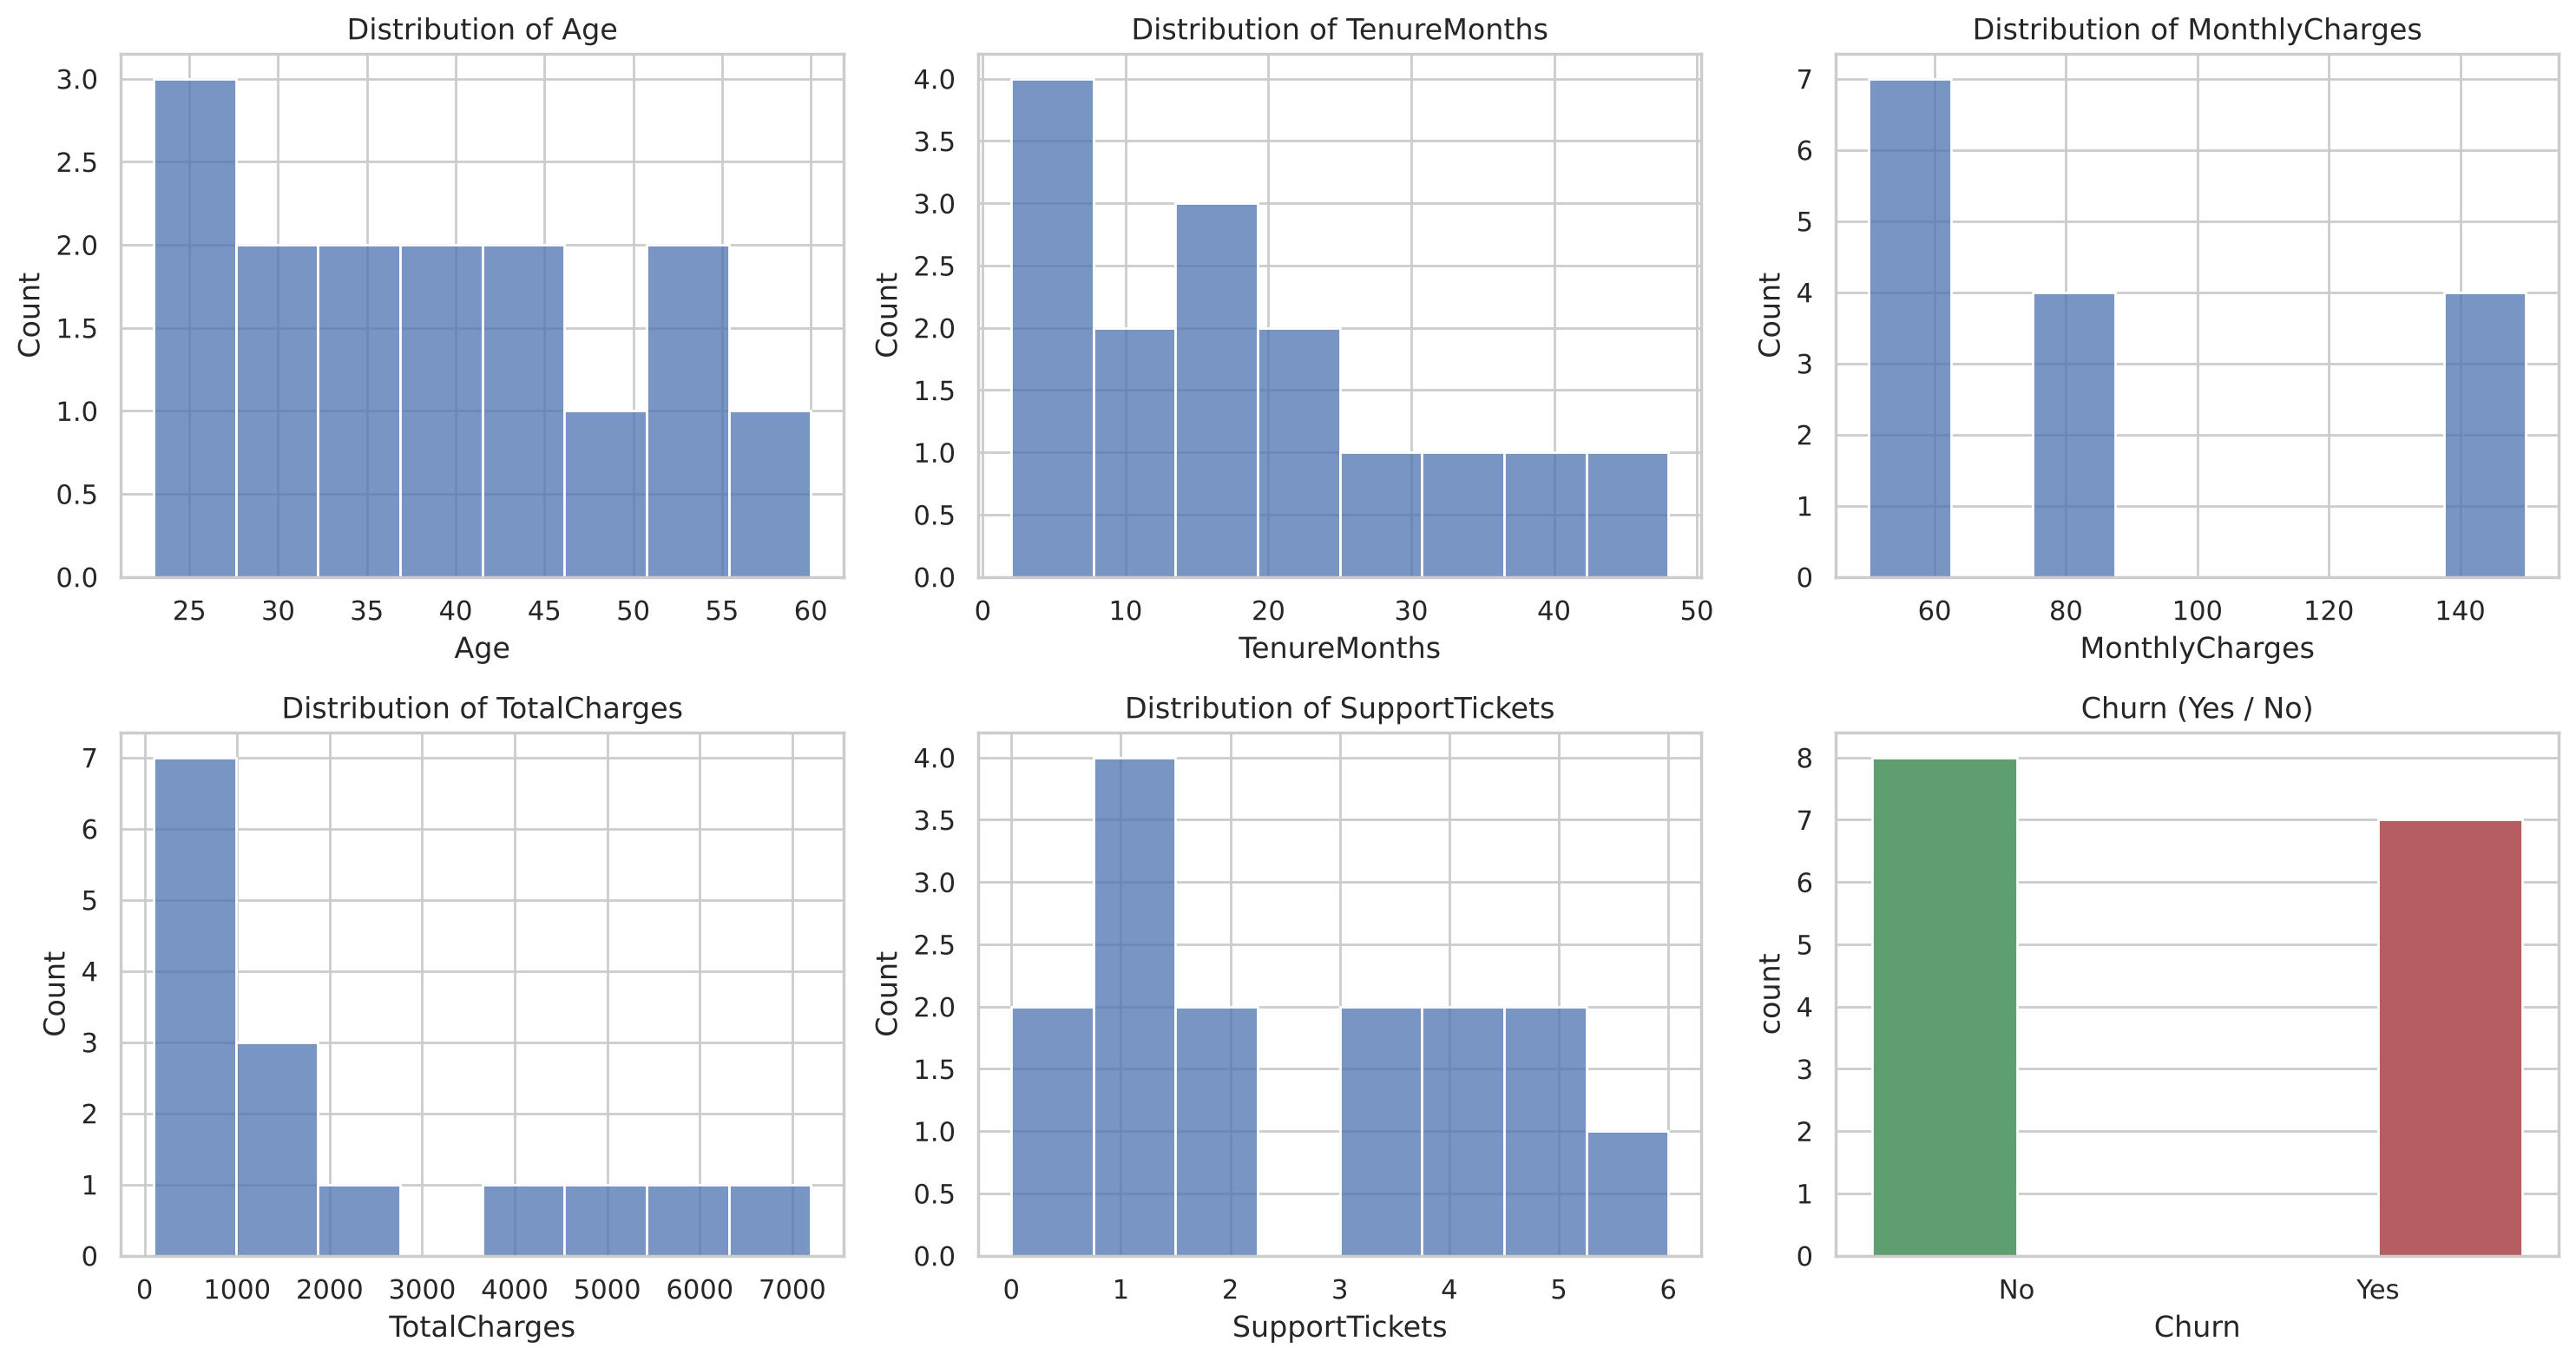

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, ["Age","TenureMonths","MonthlyCharges","TotalCharges","SupportTickets"]):
    sns.histplot(clean[c], bins=8, kde=False, ax=ax, color="#4C72B0"); ax.set_title(f"Distribution of {c}")
sns.countplot(data=clean, x="Churn", ax=axes.flat[5], palette=["#55A868","#C44E52"], hue="Churn", legend=False)
axes.flat[5].set_title("Churn (Yes / No)")
plt.tight_layout(); plt.savefig("figures/01_distributions.png", dpi=150); plt.show()

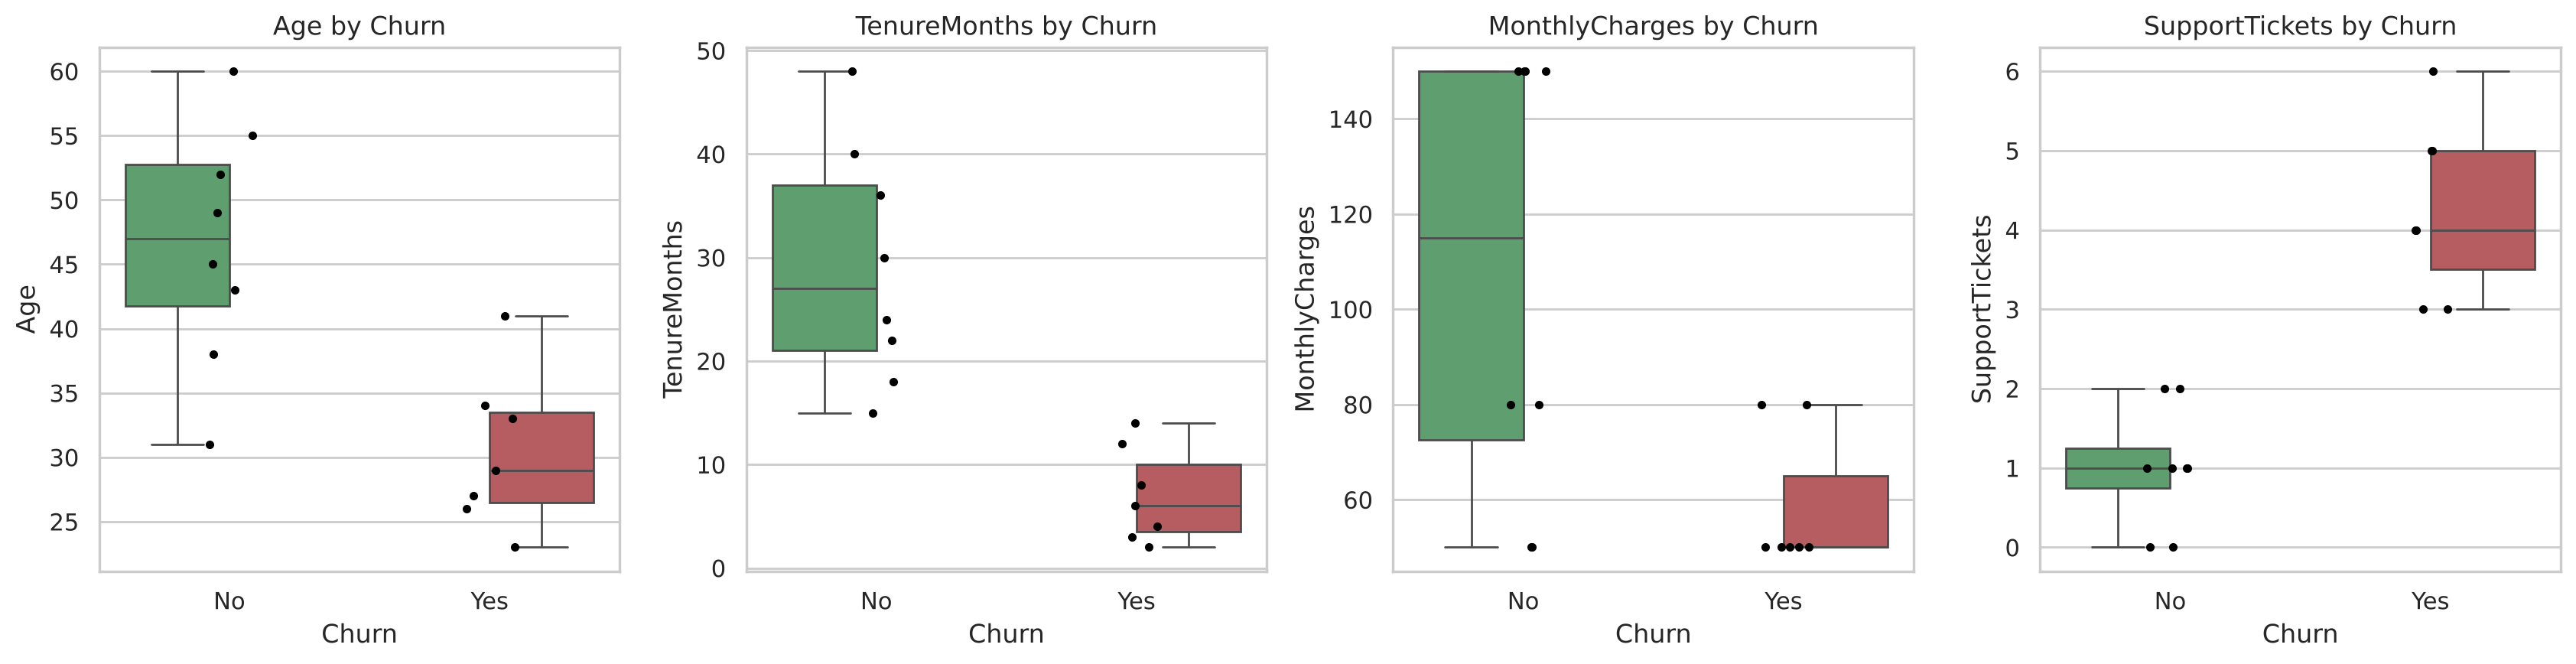

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
for ax, c in zip(axes, ["Age","TenureMonths","MonthlyCharges","SupportTickets"]):
    sns.boxplot(data=clean, x="Churn", y=c, hue="Churn", palette=["#55A868","#C44E52"], ax=ax, legend=False)
    sns.stripplot(data=clean, x="Churn", y=c, color="black", size=4, ax=ax)
    ax.set_title(f"{c} by Churn")
plt.tight_layout(); plt.savefig("figures/02_boxplots_by_churn.png", dpi=150); plt.show()

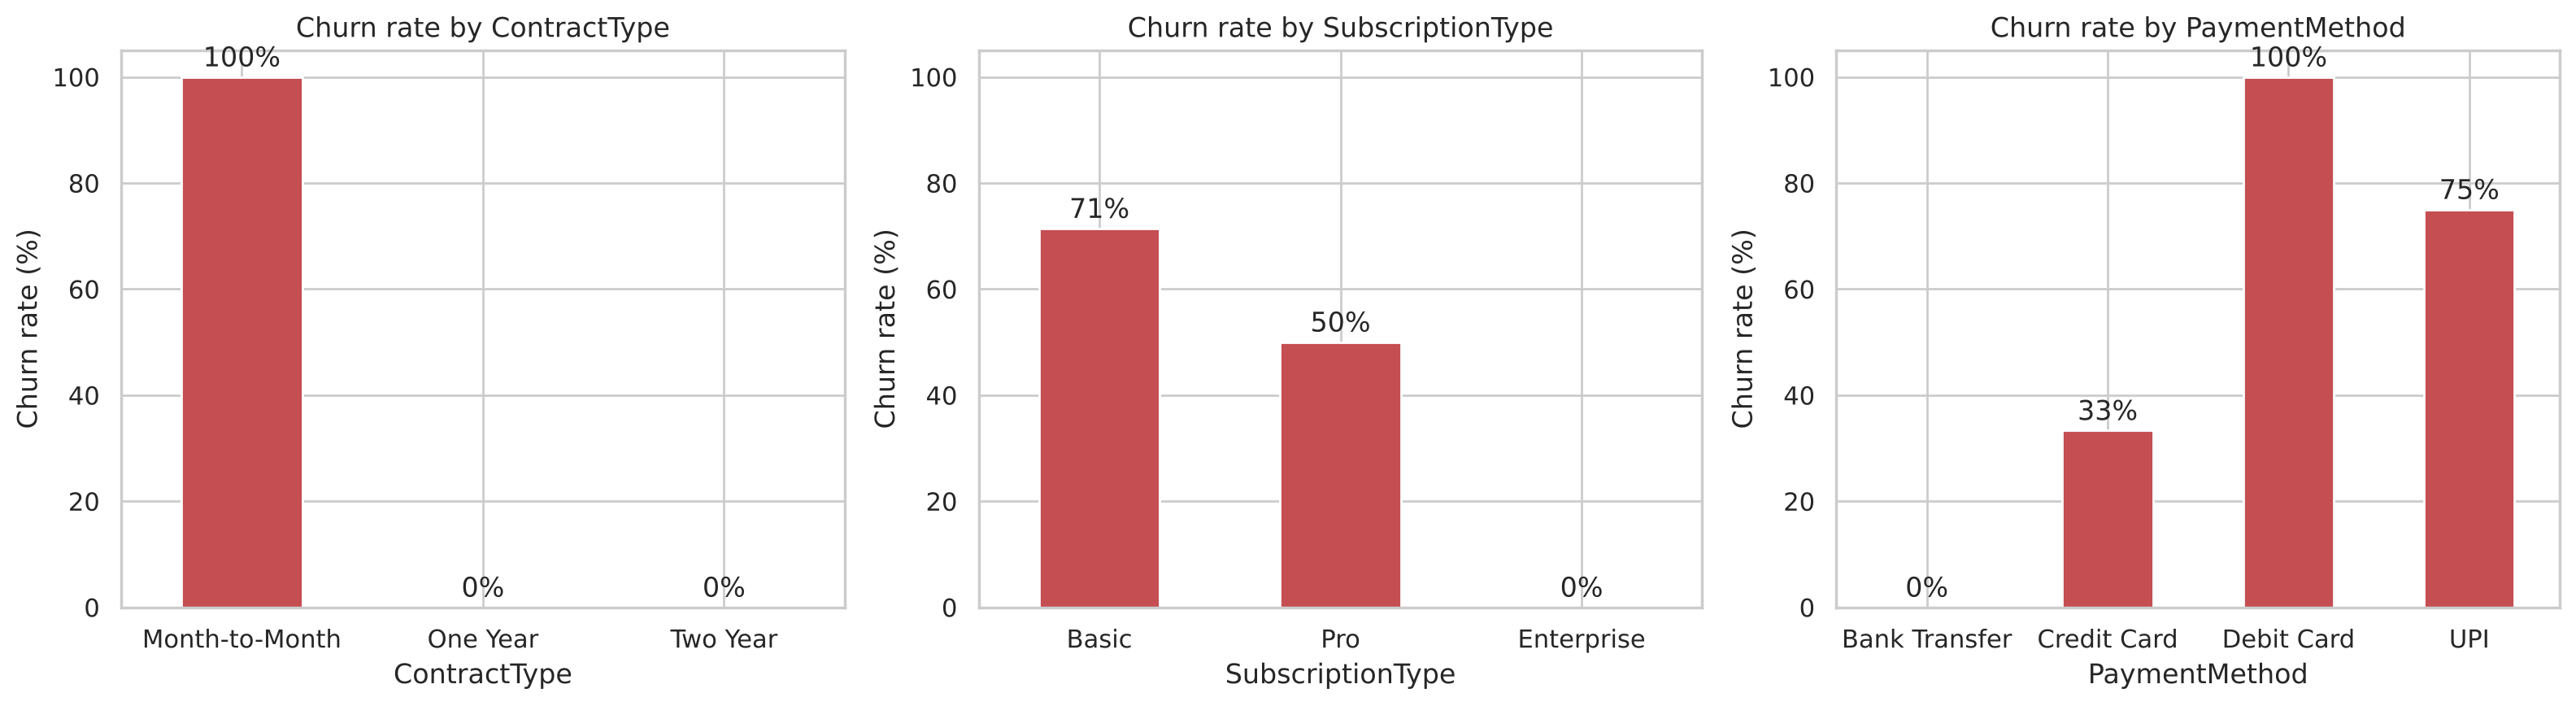

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, ["ContractType","SubscriptionType","PaymentMethod"]):
    (clean.groupby(c, observed=True)["ChurnFlag"].mean()*100).plot.bar(ax=ax, color="#C44E52", rot=0)
    ax.set_ylabel("Churn rate (%)"); ax.set_title(f"Churn rate by {c}"); ax.set_ylim(0, 105)
    for p in ax.patches: ax.annotate(f"{p.get_height():.0f}%", (p.get_x()+p.get_width()/2, p.get_height()+2), ha="center")
plt.tight_layout(); plt.savefig("figures/03_churn_rate_by_segment.png", dpi=150); plt.show()

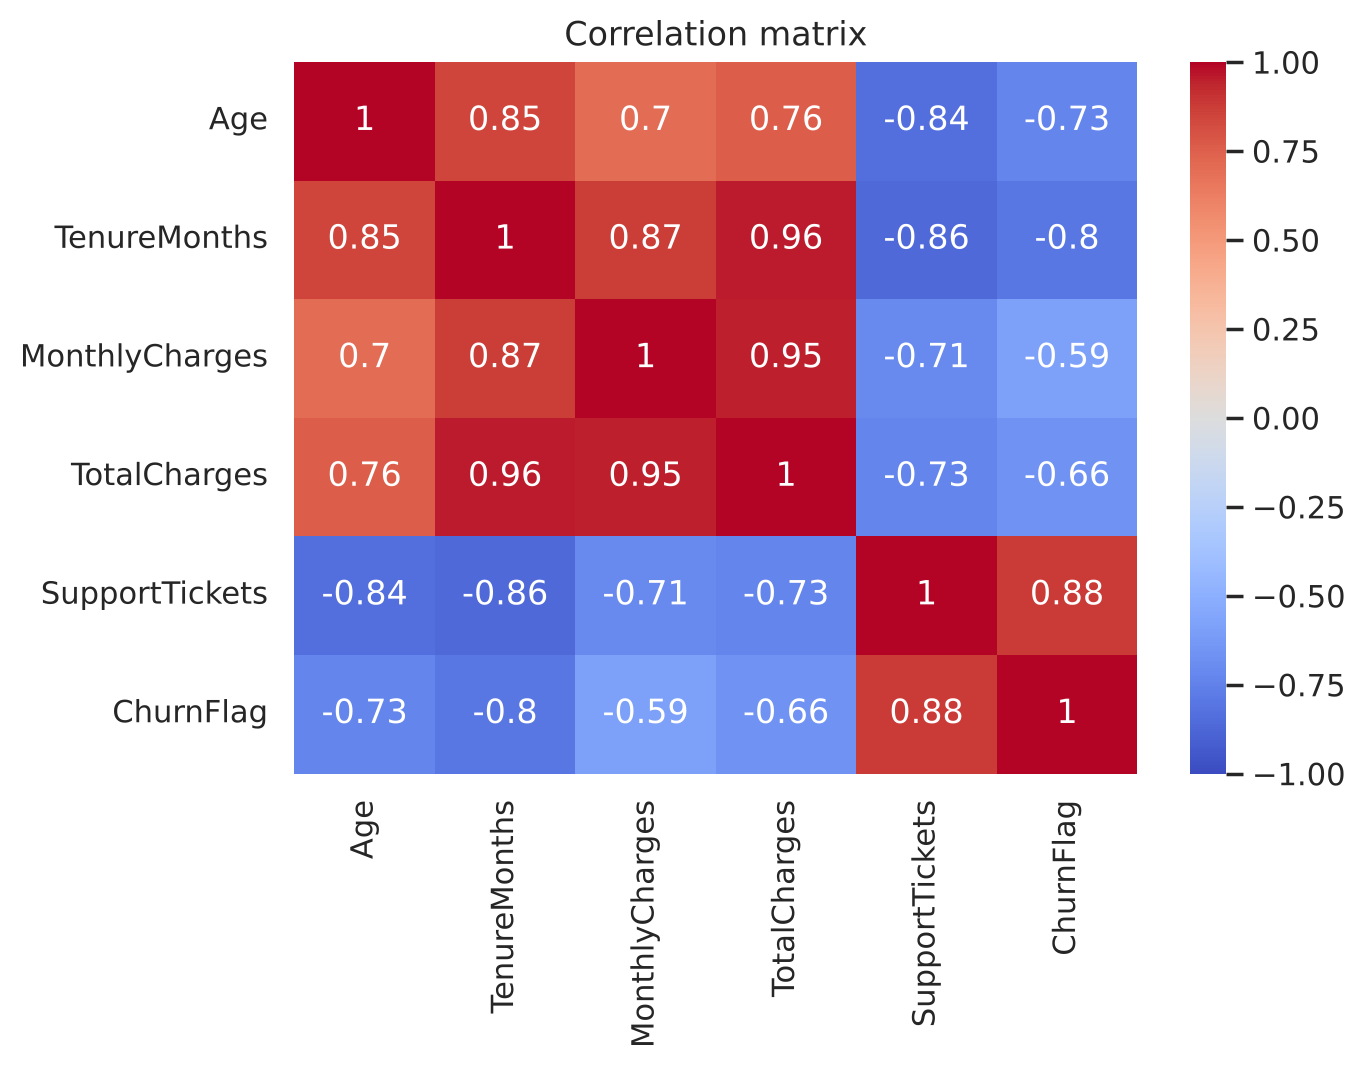

TenureMonths     -0.80
Age              -0.73
TotalCharges     -0.66
MonthlyCharges   -0.59
SupportTickets    0.88
Name: ChurnFlag, dtype: float64

In [15]:
corr = clean[["Age","TenureMonths","MonthlyCharges","TotalCharges","SupportTickets","ChurnFlag"]].corr().round(2)
plt.figure(figsize=(7, 5.5)); sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix"); plt.tight_layout(); plt.savefig("figures/04_correlation_heatmap.png", dpi=150); plt.show()
corr["ChurnFlag"].drop("ChurnFlag").sort_values()

## 6. Export

In [16]:
Path("data").mkdir(exist_ok=True)
export = clean.copy()
for c in export.select_dtypes("category"): export[c] = export[c].astype(str)
export.to_csv("data/customer_churn_clean.csv", index=False)

dictionary = pd.DataFrame([
 ("CustomerID","string","Unique customer identifier, format CUST-####","raw","Primary key; unique, 15 values"),
 ("Gender","category","Customer gender","raw","Female / Male"),
 ("Age","int","Customer age in years","raw","Valid range 18-100; observed 23-60"),
 ("TenureMonths","int","Months as a customer","raw","Observed 2-48"),
 ("SubscriptionType","ordered category","Plan tier","raw","Basic < Pro < Enterprise (one fixed price per tier)"),
 ("MonthlyCharges","float","Monthly bill (currency not stated in source)","raw","49.99 / 79.99 / 149.99"),
 ("TotalCharges","float","Lifetime billed amount","raw","Equals MonthlyCharges x TenureMonths for every row"),
 ("ContractType","ordered category","Contract length","raw","Month-to-Month < One Year < Two Year"),
 ("SupportTickets","int","Number of support tickets raised","raw","Observed 0-6"),
 ("PaymentMethod","category","Payment channel","raw","Credit Card, Debit Card, UPI, Bank Transfer"),
 ("Churn","category","Whether the customer churned","raw","Yes / No"),
 ("ChurnFlag","int","Binary churn target","derived","1 = Yes, 0 = No"),
 ("AgeBand","category","Age group","derived","18-29, 30-39, 40-49, 50+"),
 ("TenureBand","category","Tenure group","derived","0-6m, 7-12m, 13-24m, 25m+"),
 ("ExpectedTotalCharges","float","MonthlyCharges x TenureMonths","derived","Reconciliation helper"),
 ("TotalChargesGap","float","TotalCharges - ExpectedTotalCharges","derived","0.00 for all rows"),
], columns=["column","type","description","origin","notes / valid values"])
dictionary.to_csv("data/data_dictionary.csv", index=False)
dictionary

,column,type,description,origin,notes / valid values
0,CustomerID,string,"Unique customer identifier, format CUST-####",raw,"Primary key; unique, 15 values"
1,Gender,category,Customer gender,raw,Female / Male
2,Age,int,Customer age in years,raw,Valid range 18-100; observed 23-60
3,TenureMonths,int,Months as a customer,raw,Observed 2-48
4,SubscriptionType,ordered category,Plan tier,raw,Basic < Pro < Enterprise (one fixed price per ...
5,MonthlyCharges,float,Monthly bill (currency not stated in source),raw,49.99 / 79.99 / 149.99
6,TotalCharges,float,Lifetime billed amount,raw,Equals MonthlyCharges x TenureMonths for every...
7,ContractType,ordered category,Contract length,raw,Month-to-Month < One Year < Two Year
8,SupportTickets,int,Number of support tickets raised,raw,Observed 0-6
9,PaymentMethod,category,Payment channel,raw,"Credit Card, Debit Card, UPI, Bank Transfer"


## 7. Key findings

1. **Contract type is the dominant churn signal.** All 7 Month-to-Month customers churned; all 8 One-Year and Two-Year customers stayed.
2. **Churners are newer customers.** Churned customers have far shorter tenure (mean 7.0 vs 29.1 months; median 6 vs 27).
3. **Support tickets separate the groups.** Churners raised 3-6 tickets (mean 4.3); retained customers raised 0-2 (mean 1.0). Ticket volume may be an early-warning indicator.
4. **Cheaper plans churn more.** Basic: 5 of 7 churned; Pro: 2 of 4; Enterprise: 0 of 4. Plan, contract and tenure are tied together in this sample, so their effects cannot be separated.
5. **Younger customers churn more** (mean age 30 vs 47), again confounded with plan and contract.
6. **Payment method and gender** show no clear standalone pattern at this sample size.

## 8. Limitations
- **n = 15.** Percentages move massively with one customer. Treat every finding as a *hypothesis to test* on a larger extract, not a conclusion.
- The data is **synthetic** and unusually tidy: perfect separation between contract type and churn is unlikely in real data.
- Variables are strongly correlated (see heatmap), so this EDA cannot establish *causation* or isolate the independent effect of any one driver.
- Currency is not stated in the source file.

## 9. Recommended next steps
Validate on a larger real dataset, test a retention offer for Month-to-Month customers in their first six months, and trigger proactive outreach when a customer raises 3+ support tickets.